# 🎛️ Módulo 2B — Controle Sintético e Testes de Permutação Placebo *In-Space*

**Autor:** Dr. Silvio da Rosa Paula — Doutor em Economia Aplicada & Cientista de Dados

---

## 1. Construção do Gêmeo Contrafactual no Simplex (Abadie et al., 2010)

Em vez de agregar todas as regiões controle com pesos iguais, o **Controle Sintético** encontra pesos ótimos no simplex ($w_j \ge 0, \sum_{j=1}^J w_j = 1$) sobre as **8 unidades doadoras** que mantiveram o cupom de `20%` na Black Friday 2024, minimizando o erro quadrático de reprodução na janela pré-intervenção:
$$\min_{w \ge 0,\, \sum w_j = 1} \left\| \tilde y_{1, \text{pré}} - \sum_{j \in \mathcal{D}} w_j \tilde y_{j, \text{pré}} \right\|_2^2 + \lambda \|w\|_2^2$$
Para inferência não-paramétrica, executamos **Testes Placebo *In-Space***: aplicamos o mesmo algoritmo fingindo que cada uma das 8 unidades doadoras foi tratada e comparamos o salto pós/pré (*MSPE Ratio*).

Lift Controle Sintético (20% -> 30%) : +11.99% (IC 95% Placebo: [6.54%; 17.45%])
Lift Verdadeiro (DGP)                : +10.26%
RMSE Pré-Tratamento (Índice %)       : 4.52%

=== PESOS ÓTIMOS NO SIMPLEX (UNIDADES DOADORAS EM 20%) ===


,Unidade_Doadora,Peso_Simplex
0,MG_Capital__Moveis_Iluminacao,0.1984
1,SP_Interior__Textil_Objetos,0.1978
2,Centro_DF__Moveis_Iluminacao,0.1689
3,Sul_RS__Moveis_Iluminacao,0.1520
4,SP_Interior__Moveis_Iluminacao,0.1366
5,Sul_RS__Textil_Objetos,0.1173
6,MG_Capital__Textil_Objetos,0.0290
7,Centro_DF__Textil_Objetos,0.0000



=== RANKING DA RAZÃO MSPE PÓS/PRÉ (TRATADA vs. PLACEBOS IN-SPACE) ===


,unidade,tipo,ratio
0,Tratadas (Agregado),Tratada,6.695929
1,SP_Interior__Moveis_Iluminacao,Placebo (Controle),0.531397
2,MG_Capital__Textil_Objetos,Placebo (Controle),0.452390
3,Sul_RS__Textil_Objetos,Placebo (Controle),0.376671
4,Centro_DF__Moveis_Iluminacao,Placebo (Controle),0.343346
5,MG_Capital__Moveis_Iluminacao,Placebo (Controle),0.330716
6,Centro_DF__Textil_Objetos,Placebo (Controle),0.181240
7,SP_Interior__Textil_Objetos,Placebo (Controle),0.129848
8,Sul_RS__Moveis_Iluminacao,Placebo (Controle),0.109918


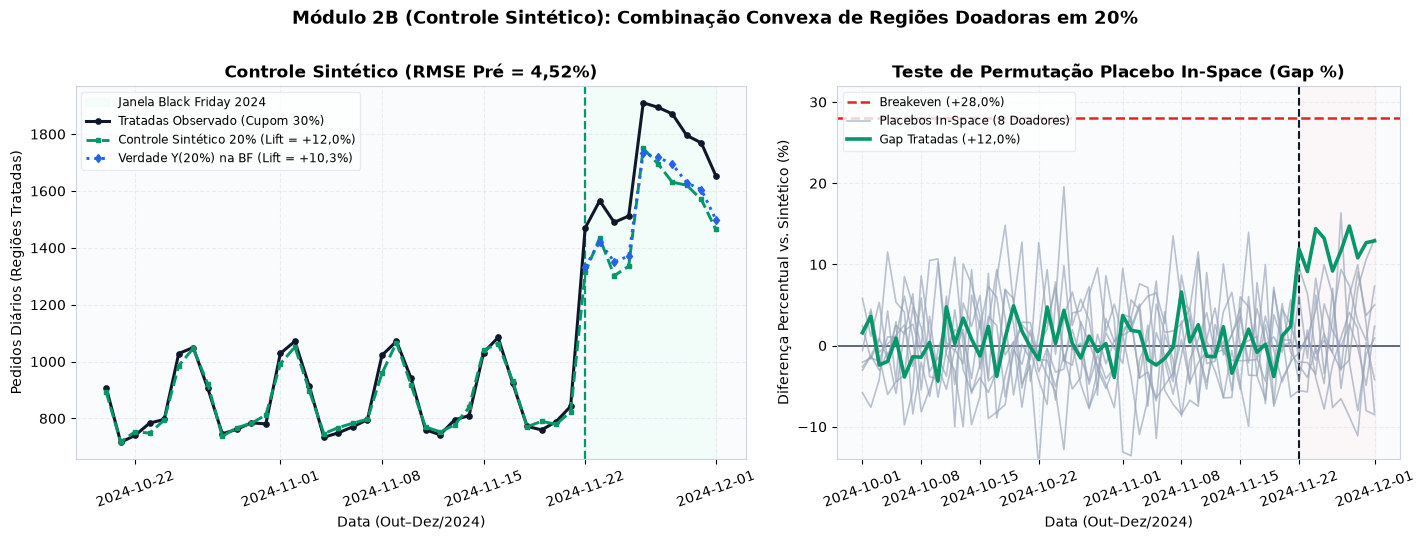

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display

from src.dgp import save_or_load_panel
from src.causal_models import fit_synthetic_control_bf
from src.visuals import plot_03_synthetic_control_placebo

PROJ_ROOT = Path(".").resolve()
df = save_or_load_panel(PROJ_ROOT / "data", seed=2025)
sc_res = fit_synthetic_control_bf(df)

print(f"Lift Controle Sintético (20% -> 30%) : +{sc_res['lift_sc_pct']:.2f}% (IC 95% Placebo: [{sc_res['ci_95_pct'][0]:.2f}%; {sc_res['ci_95_pct'][1]:.2f}%])")
print(f"Lift Verdadeiro (DGP)                : +{sc_res['true_lift_pct']:.2f}%")
print(f"RMSE Pré-Tratamento (Índice %)       : {sc_res['pre_rmse_pct']:.2f}%")

print("\n=== PESOS ÓTIMOS NO SIMPLEX (UNIDADES DOADORAS EM 20%) ===")
display(sc_res["donor_weights_df"])

print("\n=== RANKING DA RAZÃO MSPE PÓS/PRÉ (TRATADA vs. PLACEBOS IN-SPACE) ===")
display(sc_res["mspe_ratios_df"])

fig3 = plot_03_synthetic_control_placebo(sc_res, save_path=PROJ_ROOT / "img" / "03_controle_sintetico_placebo.png")
plt.show()

### Interpretação do Controle Sintético
- **Excelente aderência pré-tratamento:** a combinação convexa das unidades doadoras reproduz as flutuações semanais pré-Black Friday com `RMSE = 4,52%`.
- **Efeito significativo porém insuficiente para pagar o desconto:** o Controle Sintético estima **`+11,99%`** (muito próximo aos `+10,26%` reais), destacando-se claramente acima dos 8 placebos *in-space* na janela da Black Friday (maior razão MSPE pós/pré), mas ainda **16 pontos percentuais abaixo do *breakeven* de `+28%`**!